# BISINDO YOLO26 Classification — end-to-end executed experiment

**Scope:** exploratory single-frame Classification, A=6 kelas, B=8 kelas. Ini bukan hasil final thesis Detection.

Notebook ini menjalankan pipeline project melalui subprocess Python yang sama dengan kernel. Stdout training
ditangkap langsung sebagai output sel; results.csv, weights, prediksi dan hash menjadi artefak pendukung.
Tidak ada angka atau execution count yang diisi manual sebagai hasil training.

**Provenance:** notebook yang diserahkan dieksekusi ulang pada work directory baru. Run `.py` sebelumnya
hanya digunakan sebagai reference comparison. Bila hasil reproduksi berbeda, angka baru tetap dilaporkan apa adanya.
Notebook/log saja bukan bukti validitas ilmiah; periksa data, split, config, weights, dan metrik juga.

## Cara menjalankan lokal

1. Simpan notebook di root project bersama modul `.py` existing dan dataset/cache v3.
2. Pilih kernel **thesis_cuthbert** (`.venv-bisindo/Scripts/python.exe`).
3. Untuk run baru, ganti `WORK_NAME` di bawah ke nama folder yang belum dipakai, lalu **Run All**.
4. `RUN_NEW_EXPERIMENT=True` menjalankan prepare → technical gates → GPU/API probe → A/B 30 epoch → evaluation.
5. Folder run completed dibaca kembali tanpa retraining. Partial run tidak ditimpa; pilih nama output baru.

Hasil menggunakan weak **label metadata video**, bukan frame yang seluruhnya sudah disahkan ahli BISINDO.
Signer/sesi tidak tersedia adalah warning; file corruption, mapping, frozen split, duplicate content dan
detectable leakage tetap hard gates. Kaggle tidak dipakai untuk tuning/train/validation.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import subprocess
import sys
from datetime import datetime, timezone

import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
WORK_NAME = "experiment_yolo26_classification_notebook_20261102"
RUN_NEW_EXPERIMENT = True
WORK = (ROOT / WORK_NAME).resolve()
SOURCE = ROOT / "experiment_yolo26_v3"
REFERENCE = ROOT / "experiment_yolo26_classification_pilot"

protected = {ROOT / name for name in [
    'train', 'test', 'experiment_yolo26', 'experiment_yolo26_v2',
    'experiment_yolo26_v3', 'experiment_yolo26_pilot',
    'experiment_yolo26_training_pilot', 'experiment_yolo26_classification_pilot',
]}
if WORK.parent != ROOT or WORK in protected:
    raise ValueError("WORK_NAME harus folder baru tepat di root project, di luar semua output terdahulu")
for filename in [
    'classification_pilot.py', 'training_pilot.py', 'pilot_study.py',
    'frame_candidates.py', 'bisindo_pipeline.py',
    'experiment_yolo26_v3/split_lock.csv',
    'experiment_yolo26_v3/candidates.csv',
    'experiment_yolo26_v3/candidate_config.json',
    'experiment_yolo26_pilot/pilot_manifest_private.csv',
]:
    if not (ROOT / filename).is_file():
        raise FileNotFoundError(f"Input project belum tersedia: {filename}")
sys.path.insert(0, str(ROOT))
import classification_pilot as c

CLI_HISTORY = []
SOURCE_FILES = [
    'classification_pilot.py', 'training_pilot.py', 'pilot_study.py',
    'frame_candidates.py', 'bisindo_pipeline.py',
]
SOURCE_HASHES = {name: c.b.sha(ROOT / name) for name in SOURCE_FILES}
print("Kernel executable:", Path(sys.executable).name)
print("Python:", sys.version.split()[0])
print("Output:", WORK.name)
print("Classification only; no paid API, Detection changes, or promised B superiority.")

Kernel executable: python.exe
Python: 3.11.5
Output: experiment_yolo26_classification_notebook_20261102
Classification only; no paid API, Detection changes, or promised B superiority.


## 1. Config dan rencana eksekusi

Config diambil dari modul yang benar-benar dijalankan; tabel berikut bukan salinan parameter yang tidak terhubung ke trainer.
Epoch 30, seed 42, input 224, batch nominal 16, optimizer SGD, deterministic, tanpa crop/flip/augmentation linguistik.
Class IDs lama tetap 0–5; prefix folder numerik menjaga urutan ImageFolder.

Semua data lama A/B identik. Tambahan 120 training images B adalah kelas baru, bukan tambahan gambar kelas lama.

In [2]:
import os
from datetime import datetime, timezone

def public_text(value):
    text = str(value)
    for prefix in [str(ROOT).replace('\\', '\\\\'), str(ROOT), ROOT.as_posix()]:
        text = text.replace(prefix, '<PROJECT_ROOT>')
    return text

def should_execute(work, enabled):
    if not enabled:
        return False
    complete = (work / 'evaluation/evaluation_complete.json').is_file() and (work / 'runs/trained_models.json').is_file()
    if not complete and any((work / 'runs' / f'model_{name}').exists() for name in ['A', 'B']):
        raise RuntimeError('Partial run ditemukan. Tidak akan ditimpa/resume. Pilih WORK_NAME baru.')
    return not complete

def run_cli(command, *extra):
    reports = WORK / 'reports'
    reports.mkdir(parents=True, exist_ok=True)
    log = reports / f'notebook_{command}.log'
    suffix = 1
    while log.exists():
        suffix += 1
        log = reports / f'notebook_{command}_{suffix}.log'
    args = [sys.executable, '-u', str(ROOT / 'classification_pilot.py'), command,
            '--root', str(ROOT), '--source', str(SOURCE), '--work', str(WORK), *map(str, extra)]
    record = {'command': command, 'started_utc': datetime.now(timezone.utc).isoformat(),
              'argv': args, 'log_file': log.relative_to(WORK).as_posix(), 'returncode': None}
    CLI_HISTORY.append(record)
    print('EXECUTE:', public_text(subprocess.list2cmdline(args)), flush=True)
    child_env = dict(os.environ, PYTHONIOENCODING='utf-8', PYTHONUTF8='1')
    process = subprocess.Popen(args, cwd=str(ROOT), stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8',
                               errors='replace', env=child_env)
    try:
        with log.open('x', encoding='utf-8') as stream:
            for line in process.stdout:
                stream.write(line)
                stream.flush()
                print(public_text(line), end='', flush=True)
        record['returncode'] = process.wait()
    except BaseException:
        record['interrupted_or_failed'] = True
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        raise
    finally:
        record['finished_utc'] = datetime.now(timezone.utc).isoformat()
        close = getattr(process.stdout, 'close', None)
        if callable(close):
            close()
    if record['returncode']:
        raise subprocess.CalledProcessError(record['returncode'], args)
    print(f"COMPLETE {command}; log={record['log_file']}", flush=True)

In [3]:
EXECUTE_NEW_RUN = should_execute(WORK, RUN_NEW_EXPERIMENT)
print('Execution mode:', 'NEW EXPERIMENT' if EXECUTE_NEW_RUN else 'READ EXISTING / NO TRAINING')
if not EXECUTE_NEW_RUN:
    print('Run completed dibaca tanpa overwrite. Untuk retrain, ganti WORK_NAME.')
display(pd.Series(c.CONFIG, name='Actual controlled configuration').to_frame())
display(pd.DataFrame({'class_id': range(8), 'class_name': c.CLASSES,
                      'ImageFolder': c.folder_names(8)}))

Execution mode: NEW EXPERIMENT


,Actual controlled configuration
epochs,30
imgsz,224
batch,16
seed,42
deterministic,True
optimizer,SGD
lr0,0.01
lrf,0.01
momentum,0.937
weight_decay,0.0005


,class_id,class_name,ImageFolder
0,0,saya,00_saya
1,1,kamu,01_kamu
2,2,senang,02_senang
3,3,bingung,03_bingung
4,4,marah,04_marah
5,5,apa_kabar,05_apa_kabar
6,6,halo,06_halo
7,7,tidur,07_tidur


## 2. Pretrained Classification checkpoint, identik untuk A/B

`yolo26n-cls.pt`, ImageNet pretrained, revision dan SHA256 dipin. Reuse file lokal yang sudah tersedia;
jika tidak ada, unduh file publik dari repo resmi Ultralytics. Tidak ada API training/inference berbayar.
Checkpoint ini berbeda dari `yolo26n.pt` COCO Detection.

In [4]:
CHECKPOINT = {
    'repo_id': 'Ultralytics/YOLO26',
    'filename': 'yolo26n-cls.pt',
    'revision': '9da872c500a0a6fc9526cf09108ee249489a3895',
    'sha256': '0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81',
}
if EXECUTE_NEW_RUN:
    folder = WORK / 'checkpoints'
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint_path = folder / CHECKPOINT['filename']
    record_path = WORK / 'checkpoint.json'
    if not checkpoint_path.exists():
        cached = REFERENCE / 'checkpoints' / CHECKPOINT['filename']
        if cached.is_file():
            import shutil
            if c.b.sha(cached) != CHECKPOINT['sha256']:
                raise RuntimeError('Reference checkpoint corrupt; stop, jangan mengganti diam-diam')
            shutil.copy2(cached, checkpoint_path)
        else:
            from huggingface_hub import hf_hub_download
            checkpoint_path = Path(hf_hub_download(
                repo_id=CHECKPOINT['repo_id'], filename=CHECKPOINT['filename'],
                revision=CHECKPOINT['revision'], local_dir=str(folder),
                cache_dir=str(WORK / 'hf_cache'), token=False))
    if c.b.sha(checkpoint_path) != CHECKPOINT['sha256']:
        raise RuntimeError('Checkpoint SHA256 mismatch; training blocked')
    record = dict(CHECKPOINT, path=str(checkpoint_path.resolve()),
                  upstream_lfs_sha256=CHECKPOINT['sha256'])
    if record_path.exists() and c.read_json(record_path) != record:
        raise RuntimeError('Existing checkpoint lock berbeda; pilih output baru')
    if not record_path.exists():
        c.dump(record_path, record)
    print('Pretrained checksum verified:', CHECKPOINT['sha256'])
else:
    print('Checkpoint creation skipped; existing outputs remain unchanged.')

Pretrained checksum verified: 0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81


## 3. Frozen split, automatic frame selection, dataset A/B

60 train + 20 internal validation per kelas. Satu video satu frame. Jangan pindahkan split atau memakai Kaggle.
Source/candidate hashes dan decode diperiksa; technical flagged tetap disertakan. Label berasal dari video metadata.
Prepared images full-frame letterbox 224x224, tanpa crop gesture. Manual bounding box tidak diperlukan.

In [5]:
if EXECUTE_NEW_RUN:
    run_cli('prepare')
readiness_path = WORK / 'reports/readiness.json'
if not readiness_path.is_file():
    raise RuntimeError('Belum ada dataset. Aktifkan RUN_NEW_EXPERIMENT untuk work directory baru.')
readiness = c.read_json(readiness_path)
display(pd.DataFrame([readiness]).drop(columns=['blockers', 'warnings']))
for warning in readiness['warnings']:
    print('WARNING:', warning)
if not readiness['ready']:
    raise RuntimeError('Technical gates failed: ' + '; '.join(readiness['blockers']))
release = c.validate_release(WORK)
manifest = c.csv(WORK / 'manifest.csv')
display(manifest.groupby(['class_name', 'split', 'quality_status']).size().rename('n').to_frame())
print('Frozen release:', release['fingerprint'])
print('No semantic certification or signer-independent claim.')

EXECUTE: "<PROJECT_ROOT>\.venv-bisindo\Scripts\python.exe" -u "<PROJECT_ROOT>\classification_pilot.py" prepare --root "<PROJECT_ROOT>" --source "<PROJECT_ROOT>\experiment_yolo26_v3" --work "<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102"


Classification automatic frames: 40/640


Classification automatic frames: 80/640


Classification automatic frames: 120/640


Classification automatic frames: 160/640


Classification automatic frames: 200/640


... (11 outputs left out)

COMPLETE prepare; log=reports/notebook_prepare.log


,ready,samples,technical_flagged_n,selection_failed_n,known_signer_samples,semantic_assessed_n,known_ambiguous_n,semantic_unknown_n
0,True,640,497,0,0,0,0,640


n
class_name split quality_status    
apa_kabar  train eligible        10
                 flagged         50
           val   eligible         5
                 flagged         15
bingung    train eligible         4
                 flagged         56
           val   flagged         20
halo       train eligible        19
                 flagged         41
           val   eligible         9
                 flagged         11
kamu       train eligible        11
                 flagged         49
           val   eligible         3
                 flagged         17
marah      train eligible         6
                 flagged         54
           val   eligible         3
                 flagged         17
saya       train eligible        23
                 flagged         37
           val   eligible        11
                 flagged          9
senang     train eligible        17
                 flagged         43
           val   eligible         1
                 flagged         19
tidur      train eligible        14
                 flagged         46
           val   eligible         7
                 flagged         13

Frozen release: 2f87b3eddd101269d3bf81d07b4f35df16e3ed2ff587818ea43e193685340967
No semantic certification or signer-independent claim.


## 4. Stratified quality audit, bukan mandatory review 640 gambar

Antrean 15 random per kelas (10 train/5 val) + maksimal 5 additional flagged per kelas.
Buka HTML lokal bila ingin menilai semantik. Tidak ada raw frame/contact sheet wajah yang disematkan di notebook
publik ini; file audit tetap tersedia di disk. Semantik belum diperiksa adalah warning, bukan auto-approval.
Audit tidak mengganti frame/label atau membuang hard samples setelah melihat hasil.

In [6]:
audit = c.csv(WORK / 'audit/audit_samples.csv')
display(audit.groupby(['class_name', 'audit_group']).size().unstack(fill_value=0))
print('Audit images:', len(audit))
print('Local review UI:', public_text(WORK / 'audit/review.html'))
print('Technical flagged retained:', readiness['technical_flagged_n'], '/', len(manifest))
print('Expert semantic status remains unverified unless a separate audit is imported.')

audit_group,additional_flagged,stratified_random
class_name,,
apa_kabar,5,15
bingung,5,15
halo,5,15
kamu,5,15
marah,5,15
saya,5,15
senang,5,15
tidur,5,15


Audit images: 160
Local review UI: <PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\audit\review.html
Technical flagged retained: 497 / 640
Expert semantic status remains unverified unless a separate audit is imported.


## 5. Actual GPU, API, task, optimizer dan environment probe

Synthetic tensor saja pada probe. Tidak menghitung data ini sebagai training/validation.
CUDA harus tersedia; jika gagal, berhenti. Tidak ada silent CPU fallback.

In [7]:
if EXECUTE_NEW_RUN:
    run_cli('probe')
environment = c.read_json(WORK / 'reports/environment.json')
if not environment or not environment['ready']:
    raise RuntimeError('Environment blocked: ' + '; '.join((environment or {}).get('blockers', ['missing environment report'])))
print(public_text(json.dumps(environment, indent=2)))

EXECUTE: "<PROJECT_ROOT>\.venv-bisindo\Scripts\python.exe" -u "<PROJECT_ROOT>\classification_pilot.py" probe --root "<PROJECT_ROOT>" --source "<PROJECT_ROOT>\experiment_yolo26_v3" --work "<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102"


Creating new Ultralytics Settings v0.0.8 file  


View Ultralytics Settings with 'yolo settings' or at '<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\ultralytics_config\Ultralytics\settings.json'


Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)


{


... (44 outputs left out)

  }


}


COMPLETE probe; log=reports/notebook_probe.log


{
  "ready": true,
  "blockers": [],
  "checkpoint": {
    "repo_id": "Ultralytics/YOLO26",
    "filename": "yolo26n-cls.pt",
    "revision": "9da872c500a0a6fc9526cf09108ee249489a3895",
    "sha256": "0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81",
    "path": "<PROJECT_ROOT>\\experiment_yolo26_classification_notebook_20261102\\checkpoints\\yolo26n-cls.pt",
    "upstream_lfs_sha256": "0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81"
  },
  "task": "classify",
  "dry_forward": [
    1,
    1000
  ],
  "cuda": "12.6",
  "gpu": "NVIDIA GeForce RTX 4070 Laptop GPU",
  "optimizer": "SGD",
  "optimizer_groups": [
    {
      "lr": 0.01,
      "momentum": 0.937,
      "nesterov": true,
      "weight_decay": 0.0005
    },
    {
      "lr": 0.01,
      "momentum": 0.937,
      "nesterov": true,
      "weight_decay": 0.0
    },
    {
      "lr": 0.01,
      "momentum": 0.937,
      "nesterov": true,
      "weight_decay": 0
    }
  ],
  "packages": {
    "ultra

## 6. Training independen A dan B — live stdout

Dua model baru dari file pretrained **yang sama**. B tidak dimulai dari weights A.
30 epoch/seed 42/SGD/batch nominal 16; semua opsi sama kecuali data dan jumlah output classes.
Evaluation otomatis memakai **last.pt epoch 30** untuk keduanya. Validation terhadap best.pt yang juga dicetak
Ultralytics bukan angka utama perbandingan. Actual optimizer steps dapat berbeda karena ukuran data berbeda.

Output sel ini berasal dari subprocess yang dijalankan saat eksekusi notebook. Path workspace disamarkan
menjadi `<PROJECT_ROOT>` untuk portabilitas; raw transcript tetap tersimpan dan di-hash.

In [8]:
if EXECUTE_NEW_RUN:
    run_cli('train')
else:
    print('SKIP TRAINING: existing run inspected, no new training claimed.')
if not (WORK / 'runs/trained_models.json').is_file() or not (WORK / 'evaluation/evaluation_complete.json').is_file():
    raise RuntimeError('Dua training/evaluation belum selesai; jangan klaim metrics completed.')
trained = c.read_json(WORK / 'runs/trained_models.json')
print(public_text(json.dumps(trained, indent=2)))

EXECUTE: "<PROJECT_ROOT>\.venv-bisindo\Scripts\python.exe" -u "<PROJECT_ROOT>\classification_pilot.py" train --root "<PROJECT_ROOT>" --source "<PROJECT_ROOT>\experiment_yolo26_v3" --work "<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102"


optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)


Ultralytics 8.4.197  Python-3.11.5 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4070 Laptop GPU, 8188MiB)


engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\datasets\A, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=<PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\checkpoints\yolo26n-cls.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=model_A, nbs=16, nms=No

train: <PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\datasets\A\train... found 360 images in 6 classes  


val: <PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\datasets\A\val... found 120 images in 6 classes  


... (850 outputs left out)

Speed: 0.1ms preprocess, 0.2ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to <PROJECT_ROOT>\experiment_yolo26_classification_notebook_20261102\runs\model_B


COMPLETE train; log=reports/notebook_train.log


{
  "models": [
    {
      "model": "A",
      "path": "<PROJECT_ROOT>\\experiment_yolo26_classification_notebook_20261102\\runs\\model_A\\weights\\last.pt",
      "sha256": "560e5aeda9e822fbcdf7415c50026d82216f2500988f59b34e714bd67948109a",
      "epoch": 30,
      "initial_checkpoint_sha256": "0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81",
      "actual_optimizer_steps": 690
    },
    {
      "model": "B",
      "path": "<PROJECT_ROOT>\\experiment_yolo26_classification_notebook_20261102\\runs\\model_B\\weights\\last.pt",
      "sha256": "2c399d2060356581c199dfc705800941a6af9d5d7362b8a466f8adeffe9a0315",
      "epoch": 30,
      "initial_checkpoint_sha256": "0dd6f8dbc448870ac98a3cbb7156f923f7ce21fed3755d4019169ffffd279e81",
      "actual_optimizer_steps": 900
    }
  ],
  "release_fingerprint": "2f87b3eddd101269d3bf81d07b4f35df16e3ed2ff587818ea43e193685340967"
}


## 7. History 30 epoch dan actual optimizer steps

CSV dan curves berikut berasal dari **work directory notebook ini**, bukan hardcoded expected result.
Scope validator A enam kelas dan B delapan kelas berbeda; jangan menafsirkan dua kurva top-1 itu sebagai common6 identik.

Model A: actual per-epoch history


,epoch,time,train/loss,metrics/accuracy_top1,metrics/accuracy_top5,val/loss,lr/pg0,lr/pg1,lr/pg2
0,1,1.51067,1.58554,0.59167,0.96667,1.24666,0.003188,0.003188,0.071304
1,2,2.94918,0.68082,0.72500,0.97500,0.87491,0.006307,0.006307,0.041089
2,3,3.96018,0.21787,0.81667,1.00000,0.61974,0.009205,0.009205,0.010654
3,4,4.98686,0.19388,0.75000,0.99167,0.63179,0.009010,0.009010,0.009010
4,5,5.98705,0.13613,0.77500,1.00000,0.80671,0.008680,0.008680,0.008680
5,6,7.06758,0.22077,0.80833,0.98333,0.73083,0.008350,0.008350,0.008350
6,7,8.06811,0.16838,0.77500,0.99167,0.66631,0.008020,0.008020,0.008020
7,8,9.07245,0.19046,0.76667,0.96667,0.91886,0.007690,0.007690,0.007690
8,9,10.09690,0.14067,0.86667,0.98333,0.47133,0.007360,0.007360,0.007360
9,10,11.11480,0.15348,0.90833,1.00000,0.33238,0.007030,0.007030,0.007030


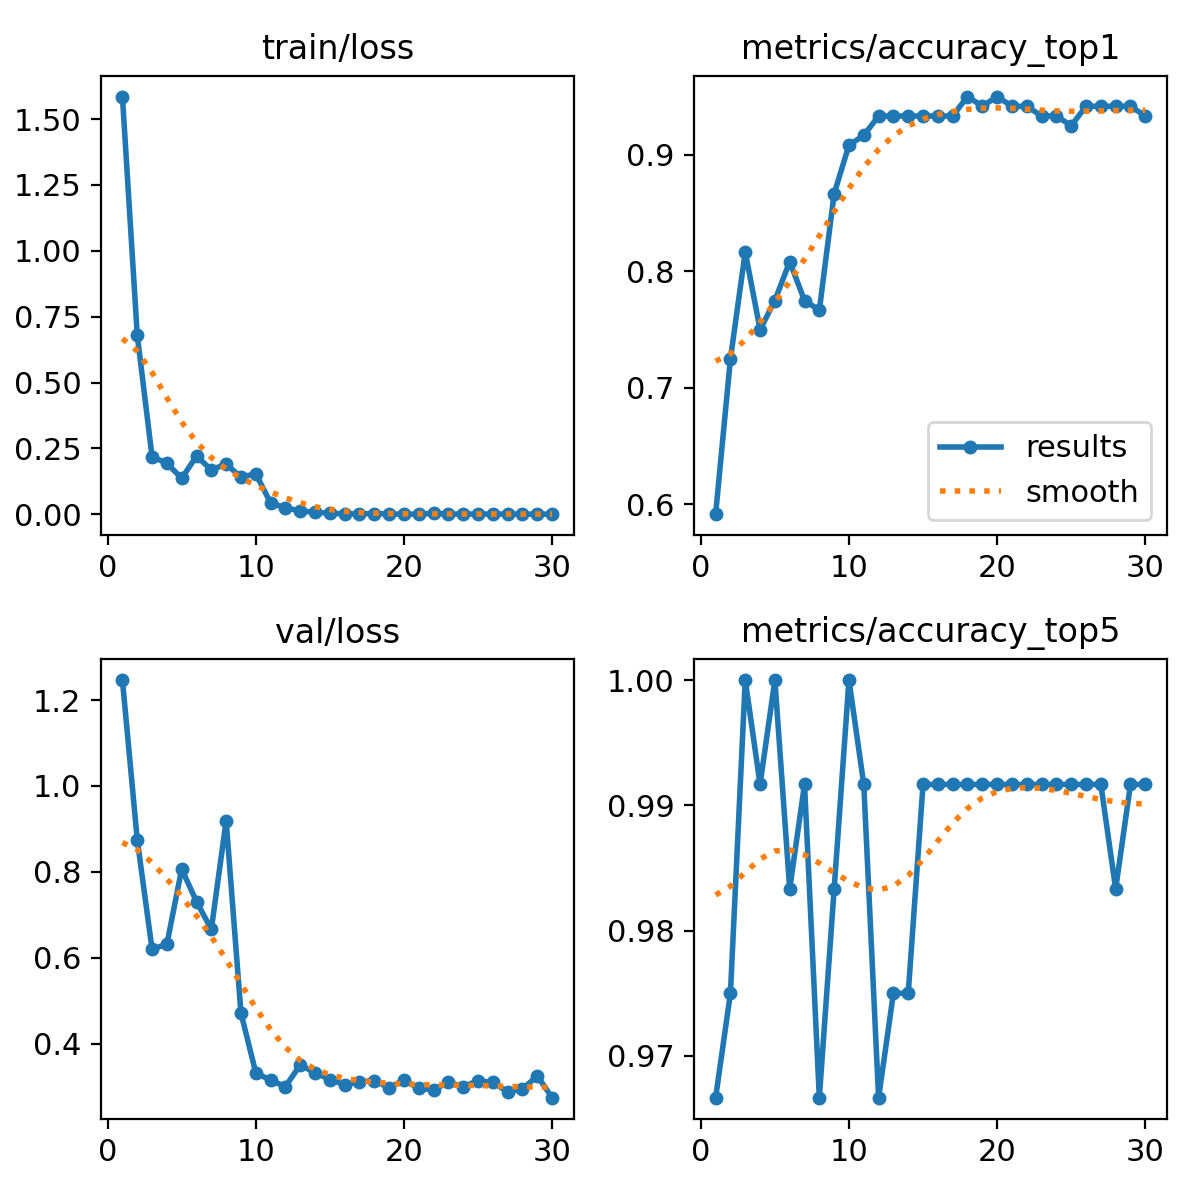

Model B: actual per-epoch history


,epoch,time,train/loss,metrics/accuracy_top1,metrics/accuracy_top5,val/loss,lr/pg0,lr/pg1,lr/pg2
0,1,1.39930,1.82898,0.56250,0.91250,1.49796,0.003222,0.003222,0.071000
1,2,2.66881,0.72196,0.83125,0.97500,0.73850,0.006339,0.006339,0.040784
2,3,3.97295,0.17947,0.48125,0.95000,1.82306,0.009236,0.009236,0.010347
3,4,5.29714,0.21706,0.78750,0.97500,0.73228,0.009010,0.009010,0.009010
4,5,6.66698,0.18646,0.63750,0.93750,1.37491,0.008680,0.008680,0.008680
5,6,8.04364,0.15550,0.55625,0.92500,1.67965,0.008350,0.008350,0.008350
6,7,9.42806,0.10212,0.89375,0.96875,0.63652,0.008020,0.008020,0.008020
7,8,10.80550,0.06146,0.81875,0.95625,0.85492,0.007690,0.007690,0.007690
8,9,12.14900,0.07906,0.88125,0.98125,0.43971,0.007360,0.007360,0.007360
9,10,13.50750,0.05372,0.78125,0.95000,0.85449,0.007030,0.007030,0.007030


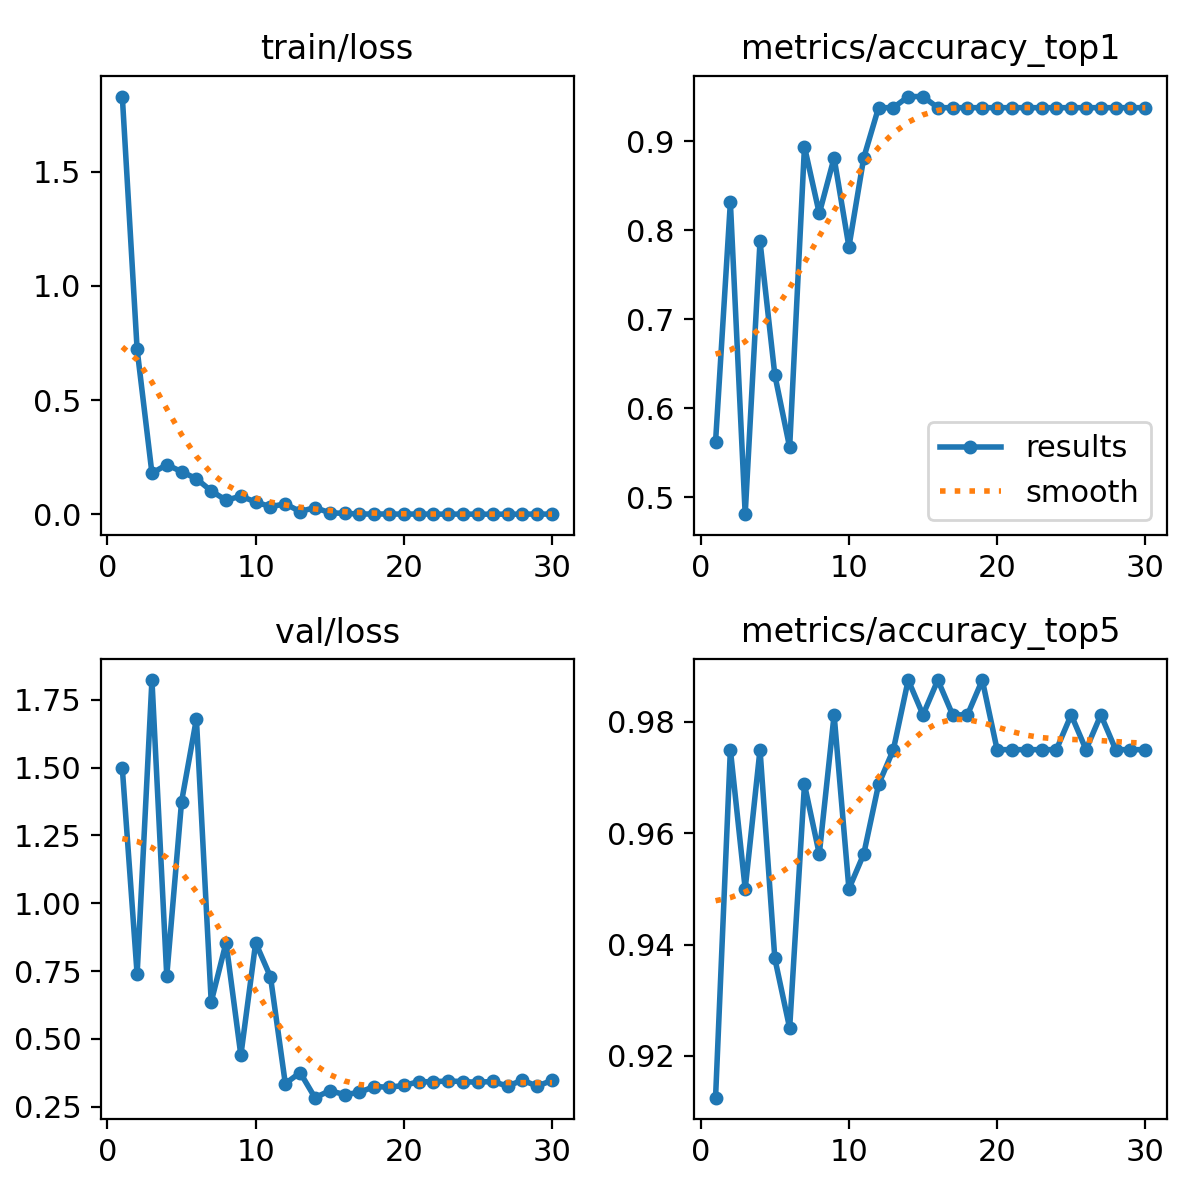

,model,completed_epochs,actual_optimizer_steps,batches_per_epoch
0,A,30,690,23
1,B,30,900,30


In [9]:
step_rows = []
for name in ['A', 'B']:
    folder = WORK / 'runs' / f'model_{name}'
    history = c.csv(folder / 'results.csv')
    assert history.epoch.astype(int).tolist() == list(range(1, 31))
    steps = c.read_json(folder / 'optimizer_steps.json')
    step_rows.append({'model': name, 'completed_epochs': len(history),
                      'actual_optimizer_steps': steps['actual_optimizer_steps'],
                      'batches_per_epoch': steps['batches_per_epoch']})
    print(f'Model {name}: actual per-epoch history')
    display(history)
    curve = folder / 'results.png'
    if curve.is_file():
        display(Image(filename=str(curve), width=1000))
display(pd.DataFrame(step_rows))

## 8. Matched common6 dan full8 evaluation

A/B common6 memakai 120 gambar yang identik. B tetap argmax atas delapan output: halo/tidur tidak dihapus.
Macro-F1 common6 dirata-ratakan atas enam GT classes yang sama; prediksi ekstra tetap merupakan errors/FN.
B/full8 memakai 160 gambar dan dilaporkan sebagai tugas berbeda.
Accuracy ini terhadap label metadata video; bukan jaminan gesture validity atau signer independence.

In [10]:
metrics = c.csv(WORK / 'evaluation/comparison_metrics.csv')
predictions = c.csv(WORK / 'evaluation/predictions.csv')
display(metrics)
shown = metrics[['model', 'scope', 'n', 'correct_n', 'accuracy', 'macro_f1', 'extra_class_predictions_n']].copy()
shown['accuracy_percent'] = 100 * shown.pop('accuracy')
display(shown)
for row in metrics.itertuples():
    output_n = 6 if row.model == 'A' else 8
    gt_n = 6 if row.scope == 'common6' else 8
    part = predictions[predictions.model.eq(row.model) & predictions.true_class_id.lt(gt_n)]
    recomputed, _, _ = c.metrics(part.true_class_id.tolist(), part.predicted_class_id.tolist(), output_n, gt_n)
    assert abs(recomputed['accuracy'] - row.accuracy) < 1e-12
    assert abs(recomputed['macro_f1'] - row.macro_f1) < 1e-12
print('PASS: saved accuracy/F1 recomputed from per-image predictions.')

,model,scope,n,correct_n,accuracy,macro_f1,macro_f1_definition,extra_class_predictions_n
0,A,common6,120,112,0.933333,0.931776,Mean F1 over fixed ground-truth classes 0..5; ...,0
1,B,common6,120,111,0.925000,0.930042,Mean F1 over fixed ground-truth classes 0..5; ...,2
2,B,full8,160,150,0.937500,0.935464,Mean F1 over fixed ground-truth classes 0..7; ...,0


,model,scope,n,correct_n,macro_f1,extra_class_predictions_n,accuracy_percent
0,A,common6,120,112,0.931776,0,93.333333
1,B,common6,120,111,0.930042,2,92.500000
2,B,full8,160,150,0.935464,0,93.750000


PASS: saved accuracy/F1 recomputed from per-image predictions.


Model A: common6; rows=video-label GT, columns=prediction


,saya,kamu,senang,bingung,marah,apa_kabar
Unnamed: 0,,,,,,
saya,18,0,0,0,0,2
kamu,0,20,0,0,0,0
senang,0,0,19,0,0,1
bingung,0,0,0,20,0,0
marah,1,3,0,1,15,0
apa_kabar,0,0,0,0,0,20


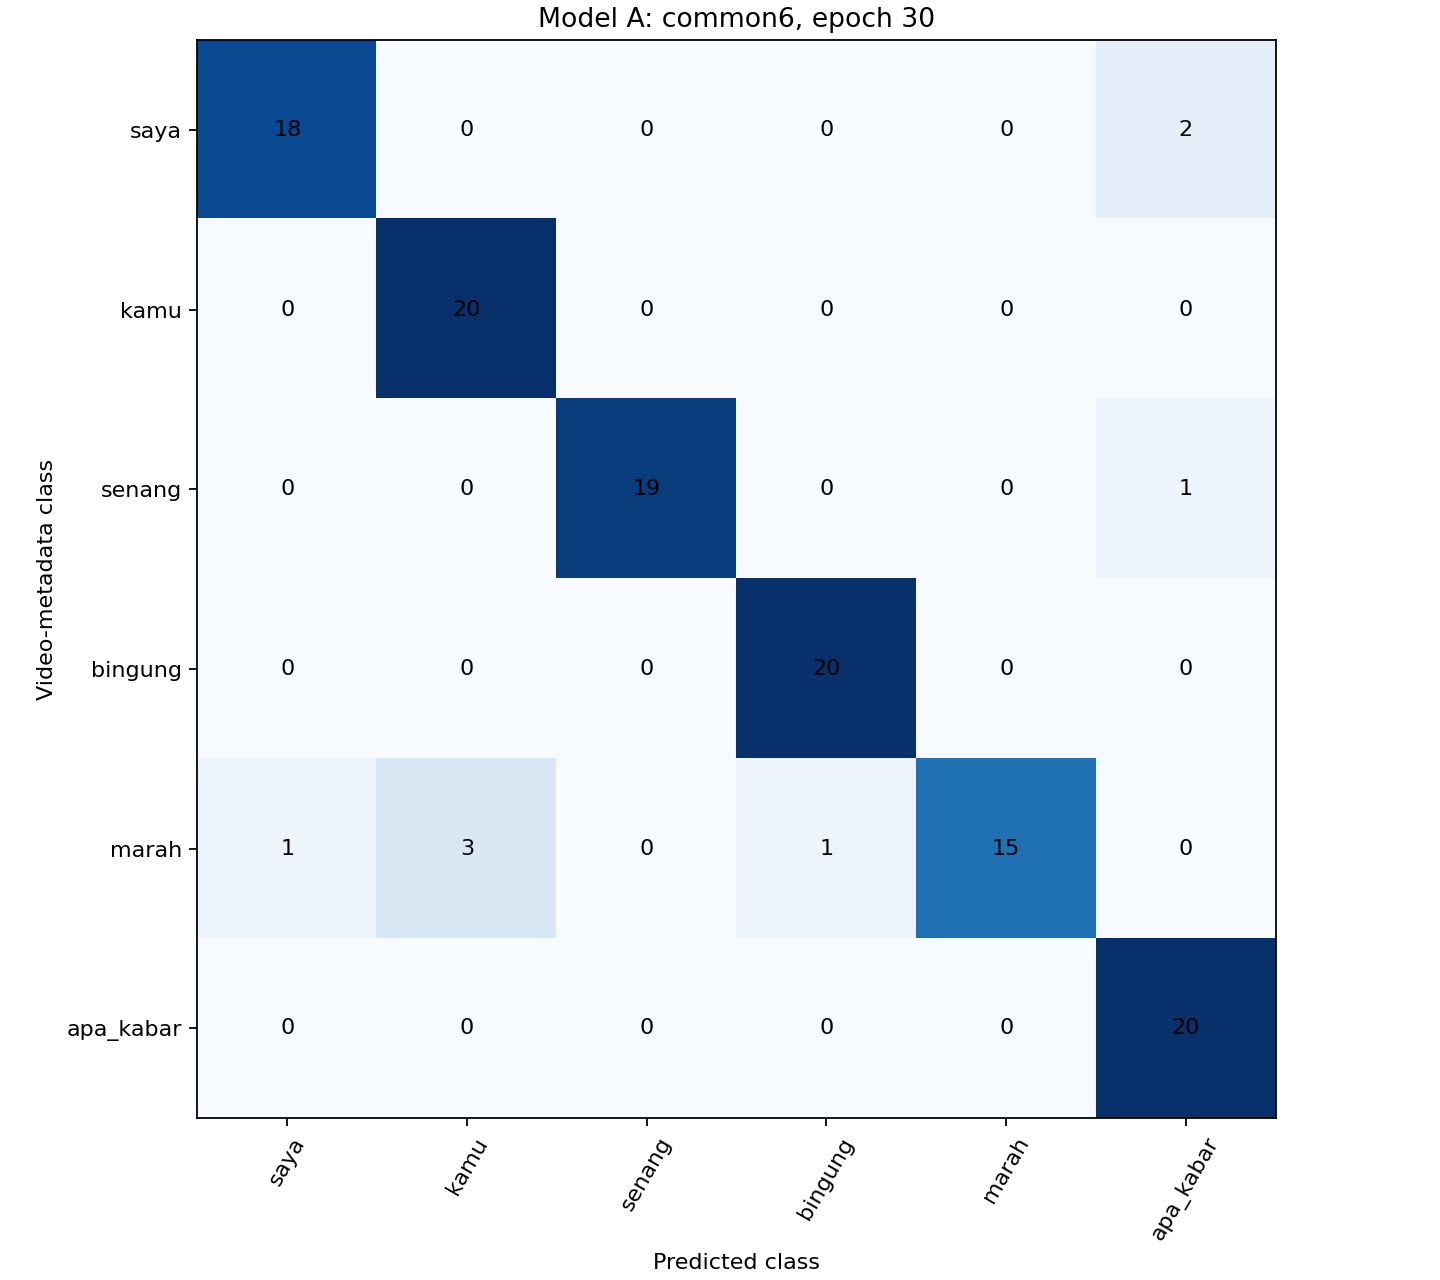

Model B: common6; rows=video-label GT, columns=prediction


,saya,kamu,senang,bingung,marah,apa_kabar,halo,tidur
Unnamed: 0,,,,,,,,
saya,18,0,0,1,0,0,0,1
kamu,0,20,0,0,0,0,0,0
senang,0,0,19,0,0,1,0,0
bingung,0,0,0,20,0,0,0,0
marah,0,2,0,2,14,1,1,0
apa_kabar,0,0,0,0,0,20,0,0
halo,0,0,0,0,0,0,0,0
tidur,0,0,0,0,0,0,0,0


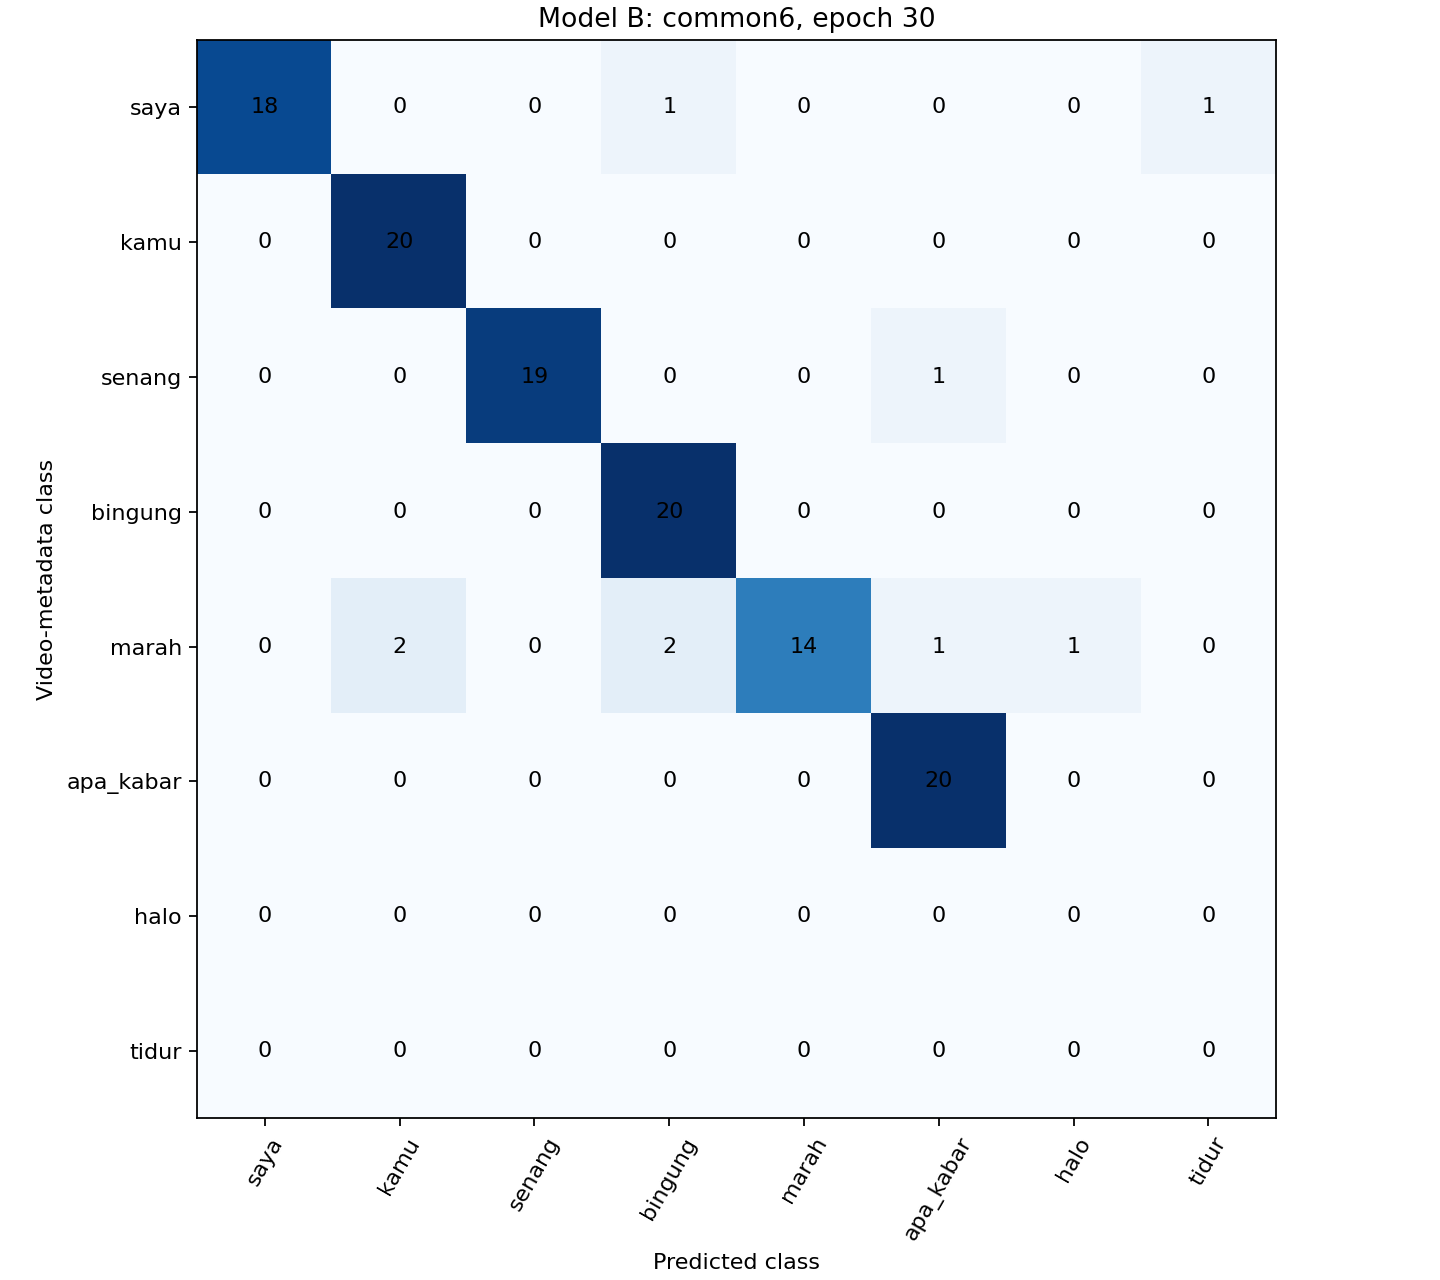

Model B: full8; rows=video-label GT, columns=prediction


,saya,kamu,senang,bingung,marah,apa_kabar,halo,tidur
Unnamed: 0,,,,,,,,
saya,18,0,0,1,0,0,0,1
kamu,0,20,0,0,0,0,0,0
senang,0,0,19,0,0,1,0,0
bingung,0,0,0,20,0,0,0,0
marah,0,2,0,2,14,1,1,0
apa_kabar,0,0,0,0,0,20,0,0
halo,0,0,0,0,0,1,19,0
tidur,0,0,0,0,0,0,0,20


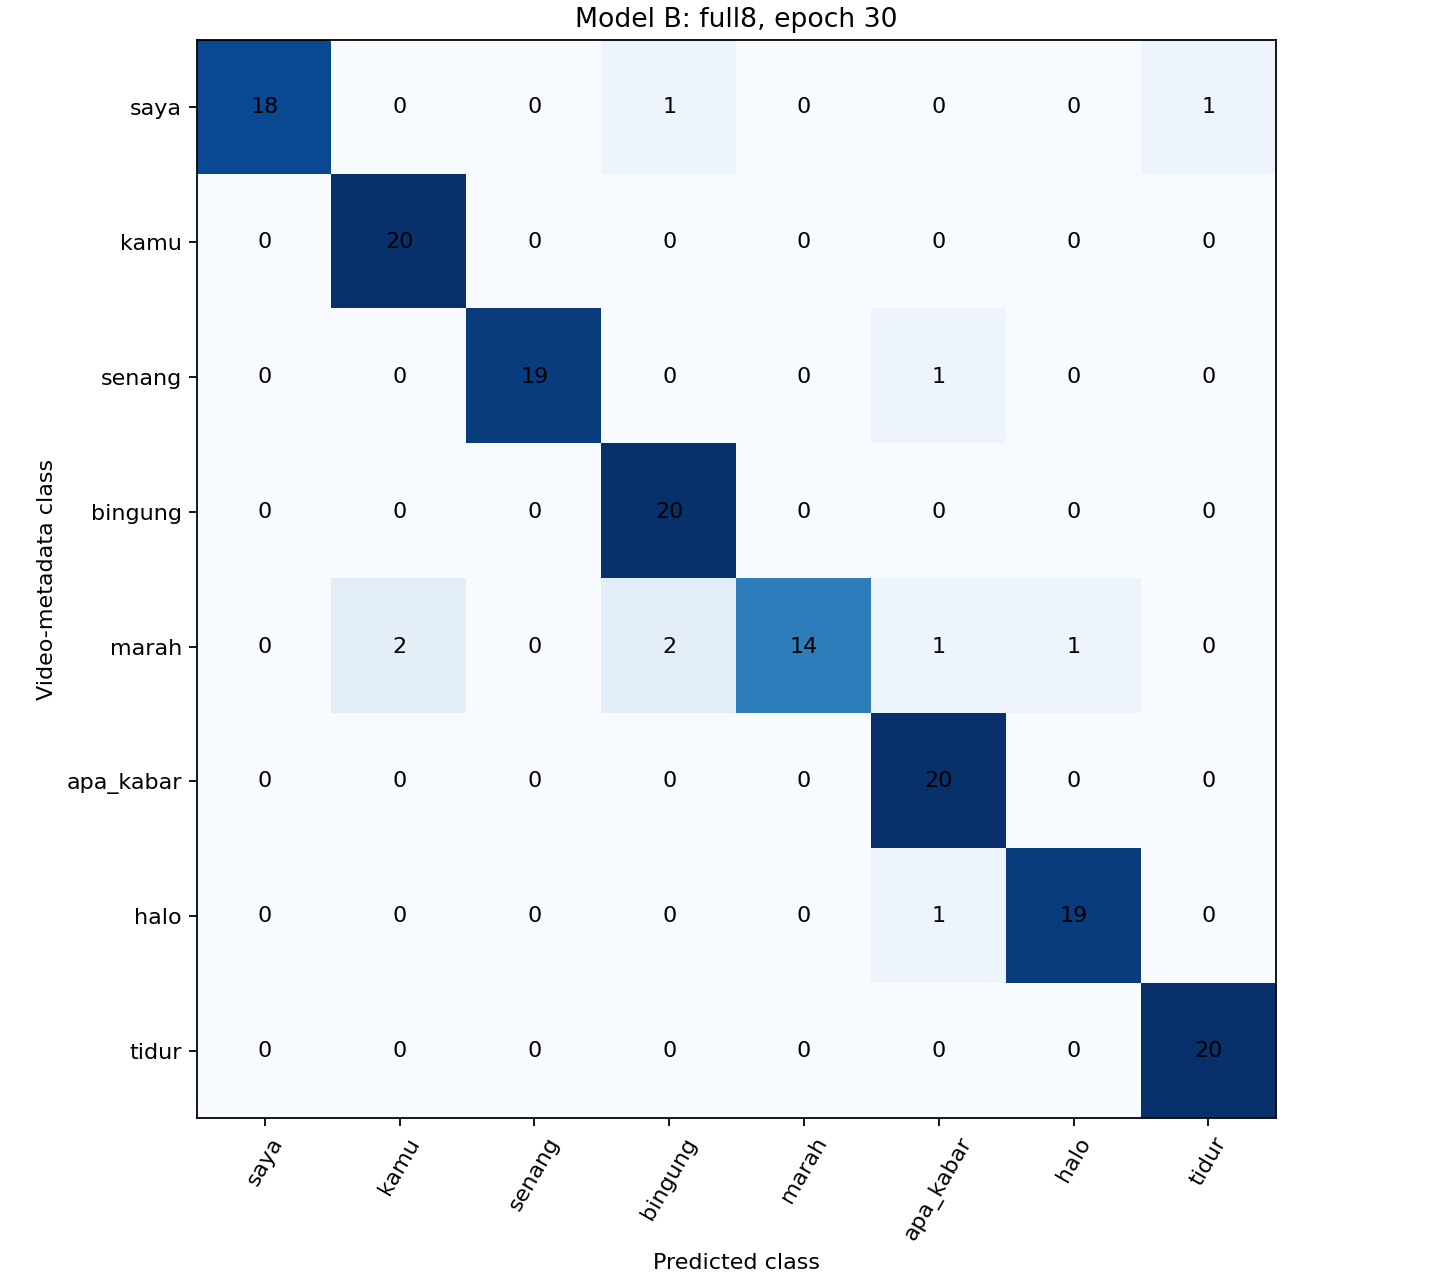

In [11]:
for name, scope in [('A', 'common6'), ('B', 'common6'), ('B', 'full8')]:
    print(f'Model {name}: {scope}; rows=video-label GT, columns=prediction')
    display(c.csv(WORK / f'evaluation/confusion_{name}_{scope}.csv').set_index('Unnamed: 0'))
    display(Image(filename=str(WORK / f'evaluation/confusion_{name}_{scope}.png'), width=800))

## 9. Per-class, paired errors, apa_kabar/halo diagnostics

Perbandingan per gambar menghindari interpretasi selisih agregat tanpa tahu contoh yang berubah.
Semua probabilitas B tetap utuh. Tidak ada frame removal, perubahan label, atau checkpoint selection berdasarkan tabel ini.

In [12]:
display(c.csv(WORK / 'evaluation/per_class_metrics.csv'))
a = predictions[predictions.model.eq('A')].set_index('sample_id')
b = predictions[predictions.model.eq('B') & predictions.true_class_id.lt(6)].set_index('sample_id')
assert set(a.index) == set(b.index) and len(a) == len(b) == 120
b = b.loc[a.index]
assert (a.true_class_id == b.true_class_id).all()
paired_counts = pd.DataFrame({
    'outcome': ['both correct', 'A only correct', 'B only correct', 'both wrong'],
    'n': [int((a.correct & b.correct).sum()), int((a.correct & ~b.correct).sum()),
          int((~a.correct & b.correct).sum()), int((~a.correct & ~b.correct).sum())],
})
display(paired_counts)
changed = a[~a.correct | ~b.correct][['true_class', 'predicted_class', 'confidence', 'correct']].add_suffix('_A')
changed = changed.join(b[['predicted_class', 'confidence', 'correct']].add_suffix('_B'))
display(changed)
diagnostic = c.csv(WORK / 'evaluation/apa_kabar_halo_diagnostics.csv')
display(diagnostic.groupby(['model', 'true_class']).correct.agg(['size', 'sum']))
display(diagnostic[~diagnostic.correct].drop(columns=['probabilities']))

,model,scope,class_id,class_name,n,tp,fp,fn,precision,recall,f1
0,A,common6,0,saya,20,18,1,2,0.947368,0.90,0.923077
1,A,common6,1,kamu,20,20,3,0,0.869565,1.00,0.930233
2,A,common6,2,senang,20,19,0,1,1.000000,0.95,0.974359
3,A,common6,3,bingung,20,20,1,0,0.952381,1.00,0.975610
4,A,common6,4,marah,20,15,0,5,1.000000,0.75,0.857143
5,A,common6,5,apa_kabar,20,20,3,0,0.869565,1.00,0.930233
6,B,common6,0,saya,20,18,0,2,1.000000,0.90,0.947368
7,B,common6,1,kamu,20,20,2,0,0.909091,1.00,0.952381
8,B,common6,2,senang,20,19,0,1,1.000000,0.95,0.974359
9,B,common6,3,bingung,20,20,3,0,0.869565,1.00,0.930233


,outcome,n
0,both correct,111
1,A only correct,1
2,B only correct,0
3,both wrong,8


,true_class_A,predicted_class_A,confidence_A,correct_A,predicted_class_B,confidence_B,correct_B
sample_id,,,,,,,
032eb994a57dd0fbf676,marah,saya,0.584985,False,halo,0.454340,False
180528e3b77a7ce444fa,marah,kamu,0.489258,False,apa_kabar,0.375513,False
180c5230aa4c11674137,saya,apa_kabar,0.715671,False,bingung,0.780389,False
1ad79dfe0ff23b2caa1a,marah,kamu,0.457211,False,bingung,0.452631,False
1fd8ed18034c48e061c4,senang,apa_kabar,0.527237,False,apa_kabar,0.660417,False
4484dfbcc18f5aac559d,marah,kamu,0.976776,False,kamu,0.999970,False
539ed2712394ef6e7607,marah,bingung,0.992908,False,bingung,0.992742,False
c344648e8dc5e8f1a15c,marah,marah,0.703673,True,kamu,0.823823,False
df79093028a6307795c2,saya,apa_kabar,0.490343,False,tidur,0.444413,False


size  sum
model true_class           
A     apa_kabar     20   20
B     apa_kabar     20   20
      halo          20   19

,model,sample_id,true_class_id,true_class,predicted_class_id,predicted_class,confidence,correct,quality_flags,quality_status
47,B,c6219c8250c8f9679ec8,6,halo,5,apa_kabar,0.816366,False,[],eligible


## 10. Comparison terhadap run sebelumnya — reference, bukan target yang dipaksakan

Hasil acuan: A/common6 112/120; B/common6 111/120; B/full8 150/160. Angka acuan hanya membaca artefak lama.
Jika reproduksi berbeda, delta tetap ditampilkan; tidak ada memilih ulang seed/checkpoint/frame agar tabel cocok atau B menang.
Kesamaan seed tidak menjamin bit-identical results lintas hardware/versi.

In [13]:
reference_file = REFERENCE / 'evaluation/comparison_metrics.csv'
if reference_file.is_file():
    reference = c.csv(reference_file)
    comparison = metrics[['model', 'scope', 'correct_n', 'accuracy', 'macro_f1']].merge(
        reference[['model', 'scope', 'correct_n', 'accuracy', 'macro_f1']],
        on=['model', 'scope'], suffixes=('_notebook', '_reference'), validate='one_to_one')
    comparison['accuracy_delta_pp'] = 100 * (comparison.accuracy_notebook - comparison.accuracy_reference)
    comparison['macro_f1_delta'] = comparison.macro_f1_notebook - comparison.macro_f1_reference
    display(comparison)
else:
    print('Reference CSV unavailable. New experiment results above remain authoritative.')

,model,scope,correct_n_notebook,accuracy_notebook,macro_f1_notebook,correct_n_reference,accuracy_reference,macro_f1_reference,accuracy_delta_pp,macro_f1_delta
0,A,common6,112,0.933333,0.931776,112,0.933333,0.931776,0.0,0.0
1,B,common6,111,0.925000,0.930042,111,0.925000,0.930042,0.0,0.0
2,B,full8,150,0.937500,0.935464,150,0.937500,0.935464,0.0,0.0


## 11. Execution provenance dan integrity checks

Simpan notebook **dengan outputs**. Selain history kernel, berikut hash source, checkpoint, prediction/log/config;
ini memungkinkan penelusuran hasil tanpa menganggap notebook sendiri sebagai bukti yang tidak dapat diedit.
Data/cache tetap prasyarat lokal; GitHub clone tanpa dataset tidak dapat mereproduksi training.

In [14]:
c.validate_release(WORK)
models = trained['models']
assert len(models) == 2 and {r['model'] for r in models} == {'A', 'B'}
assert len({r['initial_checkpoint_sha256'] for r in models}) == 1
assert models[0]['initial_checkpoint_sha256'] == CHECKPOINT['sha256']
for row in models:
    assert c.b.sha(row['path']) == row['sha256']
for filename, expected in SOURCE_HASHES.items():
    assert c.b.sha(ROOT / filename) == expected, f'Source changed during run: {filename}'
relevant = [
    'manifest.csv', 'release.json', 'checkpoint.json', 'reports/environment.json',
    'reports/experiment_config.json', 'reports/training.log',
    'runs/trained_models.json', 'runs/model_A/results.csv', 'runs/model_B/results.csv',
    'evaluation/predictions.csv', 'evaluation/comparison_metrics.csv',
]
hashes = {p: c.b.sha(WORK / p) for p in relevant}
hashes.update({entry['log_file']: c.b.sha(WORK / entry['log_file']) for entry in CLI_HISTORY})
provenance = {
    'notebook': 'BISINDO_YOLO26_Classification_End_to_End.ipynb',
    'work_directory': WORK.name,
    'mode': 'new experiment executed in notebook' if EXECUTE_NEW_RUN else 'inspect existing run; no new training claimed',
    'recorded_utc': datetime.now(timezone.utc).isoformat(),
    'python_version': sys.version.split()[0], 'source_sha256': SOURCE_HASHES,
    'release_fingerprint': release['fingerprint'], 'artifact_sha256': hashes,
    'cli_history': CLI_HISTORY, 'training_seed': c.CONFIG['seed'],
    'fully_verified_dataset': False, 'signer_independence': 'UNVERIFIED',
}
provenance_path = WORK / 'reports/notebook_execution_manifest.json'
if EXECUTE_NEW_RUN:
    if provenance_path.exists():
        raise RuntimeError('Execution manifest exists; refusing overwrite')
    c.dump(provenance_path, provenance)
elif provenance_path.is_file():
    provenance = c.read_json(provenance_path)
print(public_text(json.dumps(provenance, indent=2)))
print('PASS: release, shared images, model weights, source versions and prediction artifacts checked.')

{
  "notebook": "BISINDO_YOLO26_Classification_End_to_End.ipynb",
  "work_directory": "experiment_yolo26_classification_notebook_20261102",
  "mode": "new experiment executed in notebook",
  "recorded_utc": "2026-11-02T07:05:46.568994+00:00",
  "python_version": "3.11.5",
  "source_sha256": {
    "classification_pilot.py": "8e8a5be2f8057214772151e56db1d39479a55fd2f3c470a58c0a008a082f6e65",
    "training_pilot.py": "fa44757bd3a5813f29fea92352c146d94b7ac6ce61c9a286c370d2b31ab60446",
    "pilot_study.py": "030cb1bc7283608be9f6ab50a99010c2fd75e9901e5795384830a0c4f2ee5668",
    "frame_candidates.py": "0e4a9a636775caed2b837f37eb5781072bb108bc5b5c4beeda78417cdcdb07a7",
    "bisindo_pipeline.py": "0f8aa793bb2e91eb88b29359de81b2cbec26a682952567cd7da980997eb7c8f1"
  },
  "release_fingerprint": "2f87b3eddd101269d3bf81d07b4f35df16e3ed2ff587818ea43e193685340967",
  "artifact_sha256": {
    "manifest.csv": "e32f95a16c1d1fa9f8639680940345a3697d65706bc599426f7112eda0c23f0e",
    "release.json": "84a54

## 12. Conclusion dan batas klaim

Tidak ada aturan yang mengharuskan B menang. Semua hasil di bawah berasal dari run notebook ini.
Jangan mengganti Classification accuracy/F1 menjadi Detection mAP. Detection lama tetap terpisah.

In [15]:
display(Markdown((WORK / 'pilot_conclusion.md').read_text(encoding='utf-8')))
print('No external Kaggle evaluation, multi-seed conclusion, expert semantic certification, or real-time deployment benchmark claimed.')

# Exploratory YOLO26 classification pilot

Two independent ImageNet -> BISINDO runs; 30 epochs; seed 42. Epoch-30 last.pt used for both comparisons.
| Model | Evaluation | N | Accuracy | Macro-F1 | Extra-class errors |
|---|---|---:|---:|---:|---:|
| A | common6 | 120 | 0.9333 | 0.9318 | 0 |
| B | common6 | 120 | 0.9250 | 0.9300 | 2 |
| B | full8 | 160 | 0.9375 | 0.9355 | 0 |

Macro-F1 common6 uses the same six GT classes for both models. B keeps all eight output scores; no removal/renormalization of halo/tidur predictions.
Technical flagged frames retained: 497/640. Semantic audit assessed=0; known ambiguous/temporal ambiguity=0; unknown=640. Unknown does not mean valid.
Actual SGD steps: A=690, B=900. More data also yields more updates at equal epochs.

## apa_kabar / halo
- A/apa_kabar: 20/20 correct; wrong classes={}.
- B/apa_kabar: 20/20 correct; wrong classes={}.
- B/halo: 19/20 correct; wrong classes={'apa_kabar': 1}.

## Interpretation and next step
B minus A common6: accuracy=-0.0083; macro-F1=-0.0017. One seed is descriptive, not proof of superiority.
Full-eight accuracy=0.9375, compared with a balanced top-1 chance reference of 0.125 (not a significance test).
Results provide exploratory evidence to continue investigating classification, especially with verified semantic audits, signer metadata and multiple seeds. They do not establish thesis-methodology replacement.
Detection was not trained on a matched release, so these numbers cannot justify a causal accuracy advantage over detection or automatically returning to it. Classification labels the whole image; detection additionally localizes hands. Choose based on the thesis task and a later matched comparison.
No temporal comparator was trained. Errors may reflect bad video-to-frame labels, technical selection, visual ambiguity, signer/background cues or limited training.
Clothing/room cues recur in the audited image groups. High video-label accuracy does not establish that the model learned linguistically valid gestures. This is closed-set classification; background/unknown-gesture rejection, real-time latency and signer-independent generalization were not tested.
Before final experiments: assess semantic errors and label validity, collect participant metadata, freeze configuration, use multiple seeds and only then run external Kaggle testing.

## Limitations
- Exploratory pilot, not final thesis performance; one seed and 30 epochs.
- Labels come from frozen video metadata, not verified per-frame semantics; dataset is NOT fully verified.
- Technical flags are retained; MediaPipe hand detection is not gesture classification.
- Signer/session independence is unverified where metadata is absent; no signer-independent claim.
- Static-frame/label errors, background and signer cues may explain performance; no causal temporal claim.
- Classification and detection were not compared on a matched trained benchmark; architecture is not automatically replaced.


No external Kaggle evaluation, multi-seed conclusion, expert semantic certification, or real-time deployment benchmark claimed.


## GitHub / replikasi

Commit notebook beserta **output eksekusi asli**, modul `.py` pendukung dan test; jangan Clear All Outputs sebelum commit.
Notebook ini memakai kode project existing, bukan notebook standalone tanpa dependency/data.
Dokumentasikan cara menyediakan frozen split, video internal, candidate cache dan pretrained checkpoint yang dipin.
Dataset, raw images, cache, venv dan weights besar tidak perlu disematkan ke notebook. Gambar di notebook hanya plot agregat.
File log/config/results/predictions dan hashes dapat disertakan sebagai evidence yang sesuai kebutuhan repository.

Belum diperiksa: signer/session independence, semantic correctness setiap frame, unknown-gesture rejection,
dan real-time latency. Hasil ini exploratory, bukan final thesis performance.